<class 'pandas.DataFrame'>
RangeIndex: 81007 entries, 0 to 81006
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   product_sku_code            81007 non-null  int64
 1   customer                    81007 non-null  str  
 2   year                        81007 non-null  int64
 3   yearweek                    81007 non-null  int64
 4   nielsen_total_volume        81007 non-null  int64
 5   promotion_indicator         81007 non-null  int64
 6   top_brand                   81007 non-null  str  
 7   flavor_internal             81007 non-null  str  
 8   pack_type_internal          81007 non-null  str  
 9   pack_size_internal          81007 non-null  str  
 10  units_per_package_internal  81007 non-null  str  
 11  sku                         81007 non-null  str  
dtypes: int64(5), str(7)
memory usage: 7.4 MB


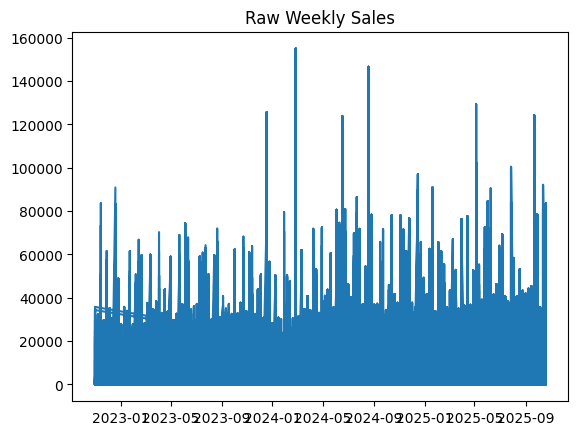

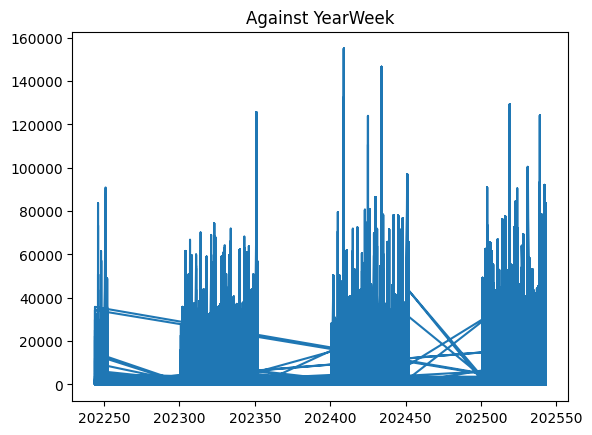

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/data.csv")

df.head()
df.info()
df["date"] = pd.to_datetime(
    df["yearweek"].astype(str) + "-1",
    format="%G%V-%u"
)

plt.figure()
plt.plot(df["date"], df["nielsen_total_volume"])
plt.title("Raw Weekly Sales")
plt.show()

plt.figure()
plt.plot(df["yearweek"], df["nielsen_total_volume"])
plt.title("Against YearWeek")
plt.show()


<Week: weekday=0>


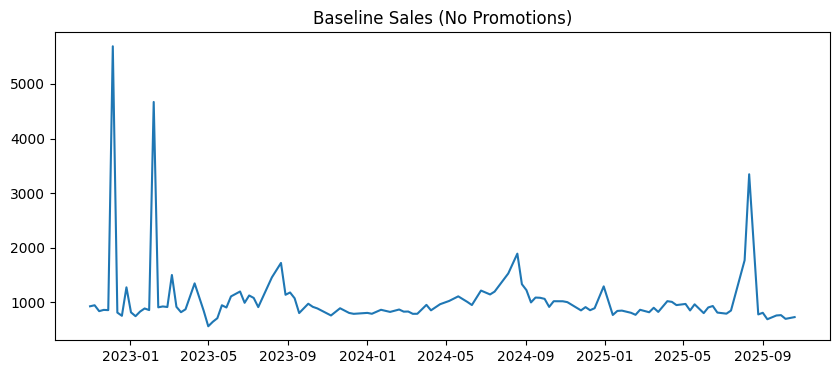

In [40]:
sku_id = df["product_sku_code"].iloc[0]
customer_id = df["customer"].iloc[0]

df_sku = df[
    (df["product_sku_code"] == sku_id) &
    (df["customer"] == customer_id)
].copy()

df_sku["date"] = pd.to_datetime(
    df_sku["yearweek"].astype(str) + "-1",
    format="%G%V-%u"
)

df_sku = df_sku.sort_values("date")
df_sku = df_sku.set_index("date")
df_sku = df_sku.rename(columns={"nielsen_total_volume": "sales"})

model_df = df_sku.asfreq("W-MON")

model_df["sales"] = model_df["sales"].interpolate()
model_df["promotion_indicator"] = model_df["promotion_indicator"].fillna(0)


#baseline_df = df_sku[df_sku["promotion_indicator"] == 0]
#baseline_df = baseline_df.asfreq("W-MON")
#baseline_df["sales"] = baseline_df["sales"].interpolate()

print(model_df.index.freq)


plt.figure(figsize=(10, 4))
plt.plot(model_df.index, model_df["sales"])
plt.title("Baseline Sales (No Promotions)")
plt.show()


date
2022-10-31   NaN
2022-11-07   NaN
2022-11-14   NaN
2022-11-21   NaN
2022-11-28   NaN
              ..
2025-09-22   NaN
2025-09-29   NaN
2025-10-06   NaN
2025-10-13   NaN
2025-10-20   NaN
Freq: W-MON, Name: trend, Length: 156, dtype: float64
date
2022-10-31    -82.168531
2022-11-07   -115.156512
2022-11-14   -109.411320
2022-11-21   -102.425743
2022-11-28   -149.149300
                 ...    
2025-09-22     -9.997858
2025-09-29     23.881950
2025-10-06    -75.651704
2025-10-13    -36.163723
2025-10-20    -57.997858
Freq: W-MON, Name: seasonal, Length: 156, dtype: float64
date
2022-10-31   NaN
2022-11-07   NaN
2022-11-14   NaN
2022-11-21   NaN
2022-11-28   NaN
              ..
2025-09-22   NaN
2025-09-29   NaN
2025-10-06   NaN
2025-10-13   NaN
2025-10-20   NaN
Freq: W-MON, Name: resid, Length: 156, dtype: float64


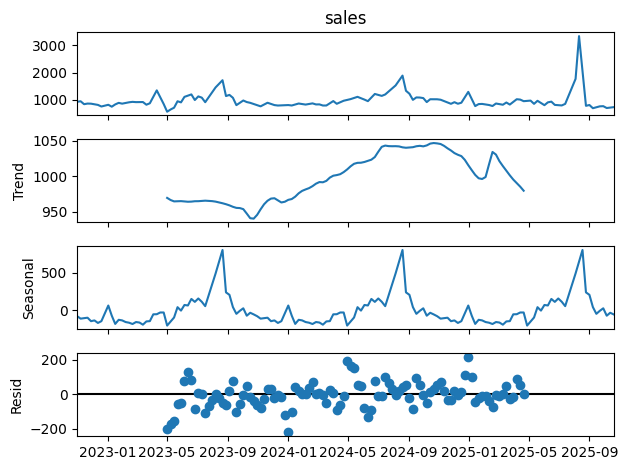

In [41]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    baseline_df["sales"],
    model="additive",
    period=52
)

print(decomposition.trend)
print(decomposition.seasonal)
print(decomposition.resid)
decomposition.plot()
plt.show()


In [42]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(
    baseline_df["sales"],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 52),
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = model.fit()
print(results.summary())


c:\Users\gw3nn\baseline-sales-modelling\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


                                     SARIMAX Results                                      
Dep. Variable:                              sales   No. Observations:                  156
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 52)   Log Likelihood                -346.971
Date:                            Mon, 09 Feb 2026   AIC                            703.942
Time:                                    00:24:55   BIC                            713.401
Sample:                                10-31-2022   HQIC                           707.531
                                     - 10-20-2025                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4678      0.178      2.634      0.008       0.120       0.816
ma.L1         -1.0196      0.391   

In [43]:
# 1. Fitted values for existing data
baseline_df["fitted_sales"] = results.fittedvalues

# 2. Forecast future weeks (e.g., 12 weeks)
forecast = results.get_forecast(steps=12)
forecast_mean = forecast.predicted_mean
forecast_ci = forecast.conf_int()


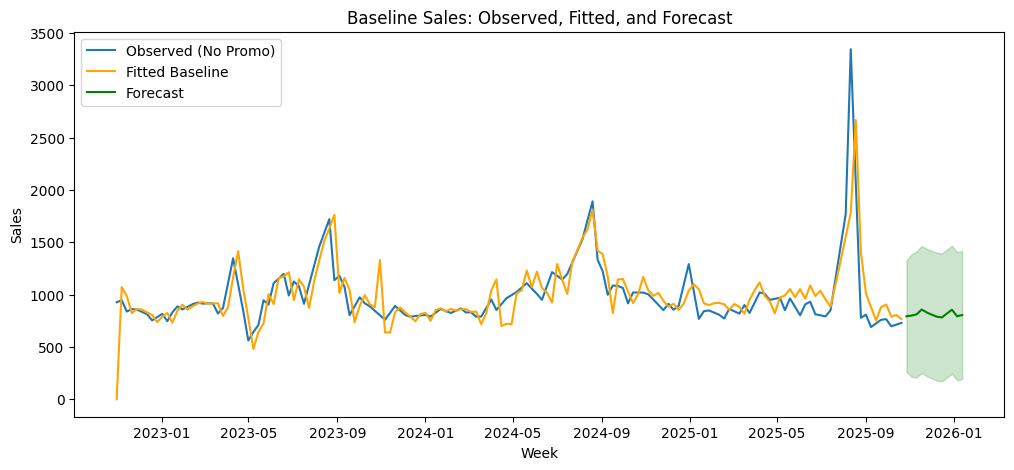

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# Actual sales (baseline only, no promotions)
plt.plot(baseline_df.index, baseline_df["sales"], label="Observed (No Promo)")

# Fitted baseline from SARIMA
plt.plot(baseline_df.index, results.fittedvalues, label="Fitted Baseline", color="orange")

# Forecast next 12 weeks
forecast_index = pd.date_range(start=baseline_df.index[-1] + pd.Timedelta(weeks=1), periods=12, freq="W-MON")
plt.plot(forecast_index, forecast_mean, label="Forecast", color="green")
plt.fill_between(forecast_index, forecast_ci.iloc[:,0], forecast_ci.iloc[:,1], color='green', alpha=0.2)

plt.title("Baseline Sales: Observed, Fitted, and Forecast")
plt.xlabel("Week")
plt.ylabel("Sales")
plt.legend()
plt.show()


In [45]:
# -------------------------------
# Train-test split (time-based)
# -------------------------------

split_index = int(len(model_df) * 0.9)

train = model_df.iloc[:split_index]
test = model_df.iloc[split_index:]

print("Train size:", len(train))
print("Test size:", len(test))

Train size: 140
Test size: 16


In [46]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(
    train["sales"],
    exog=train[["promotion_indicator"]],
    order=(1,1,1),
    seasonal_order=(1,1,1,52),
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = model.fit()


c:\Users\gw3nn\baseline-sales-modelling\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'
c:\Users\gw3nn\baseline-sales-modelling\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [47]:
# --------------------------------
# Forecast the hidden test period
# --------------------------------

n_test = len(test)

forecast = results.get_forecast(
    steps=len(test),
    exog=test[["promotion_indicator"]]
)

forecast_mean = forecast.predicted_mean
forecast_ci = forecast.conf_int()

# Align forecast index with test dates
forecast_mean.index = test.index
forecast_ci.index = test.index



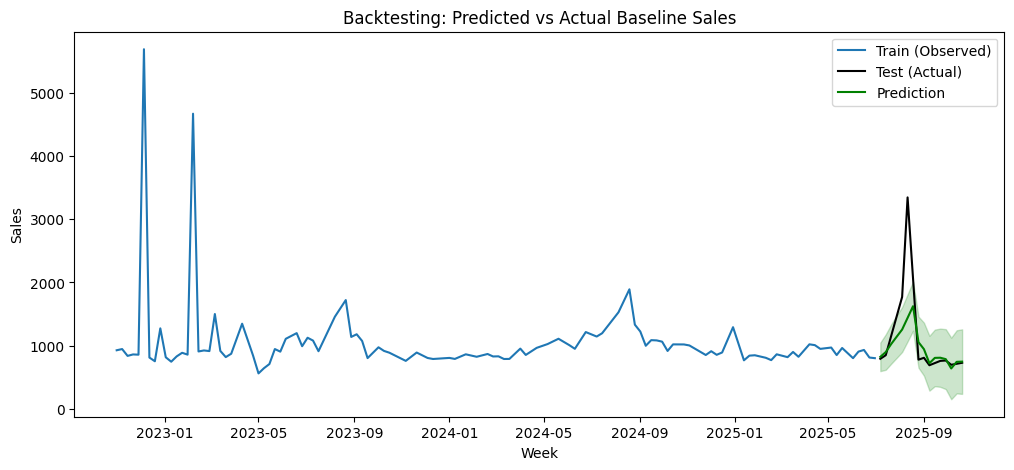

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(train.index, train["sales"], label="Train (Observed)")
plt.plot(test.index, test["sales"], label="Test (Actual)", color="black")

plt.plot(test.index, forecast_mean, label="Prediction", color="green")
plt.fill_between(
    test.index,
    forecast_ci.iloc[:, 0],
    forecast_ci.iloc[:, 1],
    color="green",
    alpha=0.2
)

plt.title("Backtesting: Predicted vs Actual Baseline Sales")
plt.xlabel("Week")
plt.ylabel("Sales")
plt.legend()
plt.show()


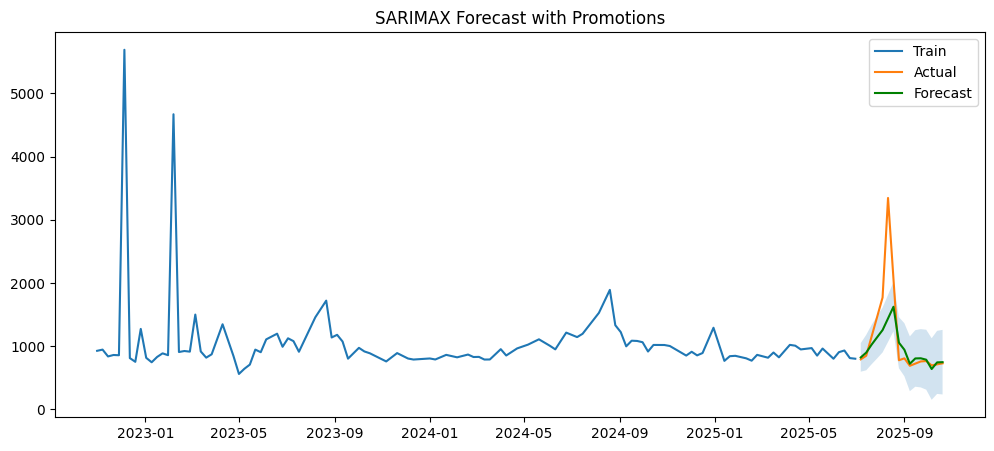

In [49]:
plt.figure(figsize=(12,5))

plt.plot(train.index, train["sales"], label="Train")
plt.plot(test.index, test["sales"], label="Actual")

plt.plot(test.index, forecast_mean, label="Forecast", color="green")
plt.fill_between(test.index,
                 forecast_ci.iloc[:,0],
                 forecast_ci.iloc[:,1],
                 alpha=0.2)

plt.legend()
plt.title("SARIMAX Forecast with Promotions")
plt.show()


In [50]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(test["sales"], forecast_mean)
rmse = np.sqrt(mean_squared_error(test["sales"], forecast_mean))
mape = np.mean(np.abs((test["sales"] - forecast_mean) / test["sales"])) * 100

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")


MAE:  255.97
RMSE: 519.80
MAPE: 15.20%


In [ ]:
from pmdarima import auto_arima

auto_model = auto_arima(
    model_df["sales"],
    exogenous=model_df[["promotion_indicator"]],  # HUGE upgrade
    seasonal=True,
    m=52,  # weekly seasonality
    trace=True,   # shows what it's testing
    stepwise=True,
    suppress_warnings=True
)

print(auto_model.summary())
